项目启动与数据接入
分析对象：原始 CSV 的接入与整体画像
    步骤 1  环境自检（版本 / 开源字体 / 数据文件）
    步骤 2  加载原始数据（100,000 行 × 9 列）
    步骤 3  数据画像 profile()：每个字段的类型、缺失、唯一值
    步骤 4  时间戳换算为波尔图本地时间（UTC -> Europe/Lisbon，夏令时）
    步骤 5  按天统计趟次量 -> ads_daily_trips
    步骤 6  按小时统计趟次量 / 活跃车辆 -> ads_hourly
    步骤 7  出图：D1_01 各日趟次分布、D1_02 小时双面板

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import taxi_common as tc

SCRIPT = "项目启动与数据接入"
tc.AUTHOR = "高帅龙 2428324009"
SOURCE = tc.source_line(SCRIPT)

In [18]:
# 环境自检
print("环境自检\n")
tc.env_self_check()
tc.apply_theme()


步骤 1 环境自检

Python      3.14.6
pandas      3.0.3
numpy       2.4.6
matplotlib  3.11.0
开源中文字体 ['Source Han Sans SC', 'Noto Sans SC']
数据文件    train_100k.csv（110 MB）


['Source Han Sans SC', 'Noto Sans SC']

In [19]:
# 加载原始数据
print("加载原始数据")
raw = tc.load_raw()
print(f"数量核对：{len(raw):,} 行 × {raw.shape[1]} 列（含解析列）")
print("原始 9 列：", [c for c in raw.columns if c in
      ["TRIP_ID", "CALL_TYPE", "ORIGIN_CALL", "ORIGIN_STAND", "TAXI_ID",
       "TIMESTAMP", "DAY_TYPE", "MISSING_DATA", "POLYLINE"]])


步骤 2 加载原始数据
数量核对：100,000 行 × 20 列（含解析列）
原始 9 列： ['TRIP_ID', 'CALL_TYPE', 'ORIGIN_CALL', 'ORIGIN_STAND', 'TAXI_ID', 'TIMESTAMP', 'DAY_TYPE', 'MISSING_DATA', 'POLYLINE']


In [26]:
# 数据画像
print("数据画像")
orig_cols = ["TRIP_ID", "CALL_TYPE", "ORIGIN_CALL", "ORIGIN_STAND", "TAXI_ID",
             "TIMESTAMP", "DAY_TYPE", "MISSING_DATA", "POLYLINE"]
prof = tc.profile(raw[orig_cols])
print(prof.to_string(index=False))

数据画像
          字段      类型   缺失数    缺失率  唯一值数                                       示例
     TRIP_ID   int64     0 0.0000 99992                      1372636858620000589
   CALL_TYPE     str     0 0.0000     3                                        C
 ORIGIN_CALL float64 79038 0.7904  8160                                  31508.0
ORIGIN_STAND float64 50689 0.5069    62                                      7.0
     TAXI_ID   int64     0 0.0000   430                                 20000589
   TIMESTAMP   int64     0 0.0000 96801                               1372636858
    DAY_TYPE     str     0 0.0000     1                                        A
MISSING_DATA    bool     0 0.0000     1                                    False
    POLYLINE     str     0 0.0000 99577 [[-8.618643,41.141412],[-8.618499,41.141


In [21]:
# 时间戳换算
print("时间戳换算")
print("UTC   ：", raw["ts_utc"].min(), "~", raw["ts_utc"].max())
print("里斯本：", raw["ts_local"].min(), "~", raw["ts_local"].max())
print("（7 月为夏令时 UTC+1；类比信令版 +8 小时）")


步骤 4 时间戳换算
UTC   ： 2013-07-01 00:00:53+00:00 ~ 2013-07-21 19:26:29+00:00
里斯本： 2013-07-01 01:00:53+01:00 ~ 2013-07-21 20:26:29+01:00
（7 月为夏令时 UTC+1；类比信令版 +8 小时）


In [22]:
# 按天统计
print("按天统计")
daily = raw.groupby("date").agg(
    趟次数=("TRIP_ID", "size"),
    活跃车辆=("TAXI_ID", "nunique"),
).reset_index()
daily["趟次占比"] = daily["趟次数"] / daily["趟次数"].sum()
daily["车均趟次"] = (daily["趟次数"] / daily["活跃车辆"]).round(1)
print(daily.to_string(index=False))

top = daily.sort_values("趟次数", ascending=False).iloc[0]
first, last = daily.iloc[0], daily.iloc[-1]
print(f"\n最高峰 {top['date']}：{top['趟次数']:,} 趟（{top['趟次占比']:.1%}）；"
      f"首尾日 {first['趟次数']:,}/{last['趟次数']:,}，末日为不完整天")


步骤 5 按天统计
      date  趟次数  活跃车辆    趟次占比  车均趟次
2013-07-01 4622   395 0.04622  11.7
2013-07-02 4620   403 0.04620  11.5
2013-07-03 4708   407 0.04708  11.6
2013-07-04 5205   406 0.05205  12.8
2013-07-05 5680   410 0.05680  13.9
2013-07-06 5296   382 0.05296  13.9
2013-07-07 4684   330 0.04684  14.2
2013-07-08 4717   404 0.04717  11.7
2013-07-09 4645   401 0.04645  11.6
2013-07-10 4779   412 0.04779  11.6
2013-07-11 5127   407 0.05127  12.6
2013-07-12 5232   411 0.05232  12.7
2013-07-13 4782   386 0.04782  12.4
2013-07-14 3943   335 0.03943  11.8
2013-07-15 4428   410 0.04428  10.8
2013-07-16 4517   407 0.04517  11.1
2013-07-17 4454   409 0.04454  10.9
2013-07-18 4945   411 0.04945  12.0
2013-07-19 5136   414 0.05136  12.4
2013-07-20 4978   385 0.04978  12.9
2013-07-21 3502   330 0.03502  10.6

最高峰 2013-07-05：5,680 趟（5.7%）；首尾日 4,622/3,502，末日为不完整天


In [23]:
# 按小时统计
print("按小时统计")
hourly = raw.groupby("hour").agg(
    趟次数=("TRIP_ID", "size"),
    活跃车辆=("TAXI_ID", "nunique"),
).reindex(range(24), fill_value=0)
print(hourly.to_string())
peak_h = int(hourly["趟次数"].idxmax())
low_h = int(hourly["趟次数"].idxmin())
print(f"\n高峰 {peak_h} 点 {hourly.loc[peak_h, '趟次数']:,} 趟；"
      f"低谷 {low_h} 点 {hourly.loc[low_h, '趟次数']:,} 趟")


步骤 6 按小时统计
       趟次数  活跃车辆
hour            
0     2914   260
1     2856   257
2     2635   254
3     2702   260
4     3547   274
5     2980   291
6     2625   317
7     2758   349
8     4525   387
9     5838   412
10    6045   415
11    5617   416
12    5046   413
13    4944   410
14    5586   415
15    5641   416
16    5532   415
17    5202   416
18    4683   413
19    4382   390
20    3913   339
21    3682   319
22    3327   285
23    3020   272

高峰 10 点 6,045 趟；低谷 6 点 2,625 趟


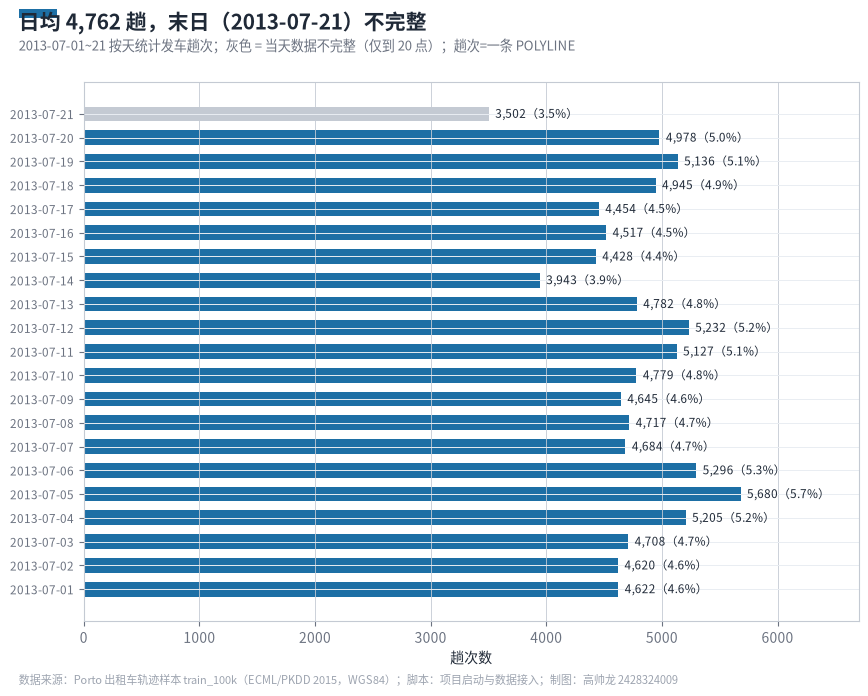

In [24]:
# 各日趟次分布
fig, ax = plt.subplots(figsize=(10, 7), dpi=100)
colors = [tc.GRAY if d == daily["date"].iloc[-1] else tc.MAIN for d in daily["date"]]
bars = ax.barh(daily["date"], daily["趟次数"], color=colors, height=0.62)
vmax = daily["趟次数"].max()
for i, (_, r) in enumerate(daily.iterrows()):
    ax.text(r["趟次数"] + vmax * 0.01, i,
            f"{r['趟次数']:,}（{r['趟次占比']:.1%}）",
            va="center", fontsize=8.5, color=tc.INK)
ax.set_xlim(0, vmax * 1.18)
ax.set_xlabel("趟次数")
ax.grid(axis="x", color=tc.GRAY, lw=0.6)
ax.set_yticks(range(len(daily)))
ax.set_yticklabels(list(daily["date"]), fontsize=8.5)
tc.finish(
    fig,
    f"日均 {daily['趟次数'].mean():,.0f} 趟，末日（{daily['date'].iloc[-1]}）不完整",
    "2013-07-01~21 按天统计发车趟次；灰色 = 当天数据不完整（仅到 20 点）；趟次=一条 POLYLINE",
    SOURCE, "D1_01_各日趟次分布.png")
plt.show()

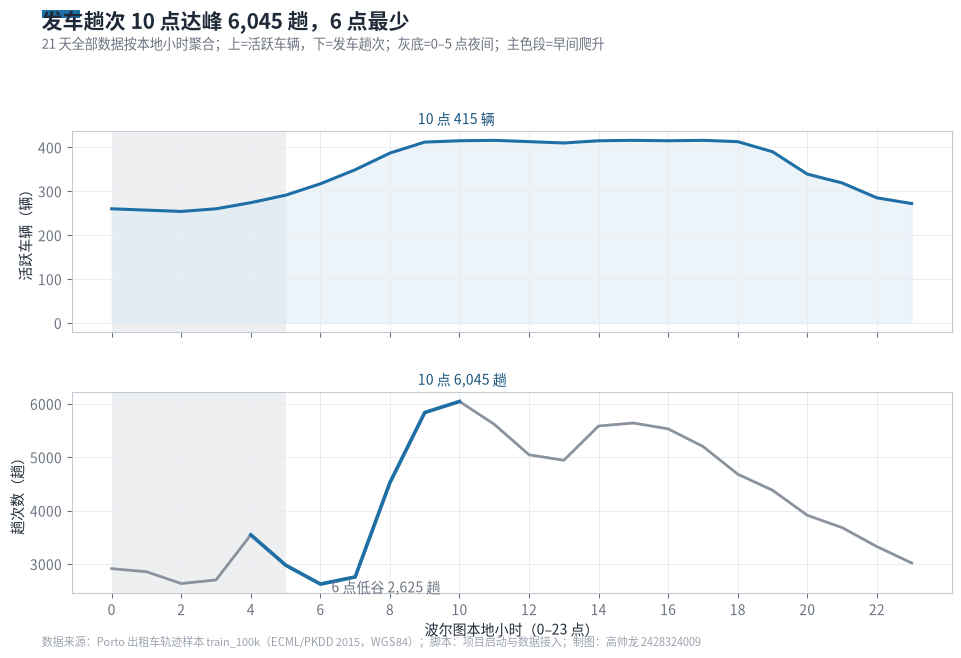


完成：图片已保存至 C:\Users\GSL\Desktop\taxi_analysis\image


In [25]:
# 小时双面板
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True)
fig.subplots_adjust(left=0.09, right=0.97, top=0.80, bottom=0.10, hspace=0.30)
for ax in (ax1, ax2):
    ax.axvspan(0, 5, color=tc.GRAY, alpha=0.30, lw=0, zorder=0)   # 夜间
ax1.plot(hourly.index, hourly["活跃车辆"], color=tc.MAIN, lw=2.2)
ax1.fill_between(hourly.index, hourly["活跃车辆"], color=tc.MAIN_LIGHT, alpha=0.5)
ax1.set_ylabel("活跃车辆（辆）", fontsize=10)
ax1.annotate(f"{peak_h} 点 {hourly.loc[peak_h,'活跃车辆']:,} 辆",
             (peak_h, hourly.loc[peak_h, "活跃车辆"]),
             xytext=(-30, 12), textcoords="offset points", color=tc.MAIN_DARK)

ax2.plot(hourly.index, hourly["趟次数"], color=tc.GRAY_DARK, lw=2)
ax2.plot(hourly.loc[4:peak_h].index, hourly.loc[4:peak_h, "趟次数"],
         color=tc.MAIN, lw=2.6)
ax2.set_ylabel("趟次数（趟）", fontsize=10)
ax2.set_xlabel("波尔图本地小时（0–23 点）", fontsize=10)
ax2.set_xticks(range(0, 24, 2))
ax2.annotate(f"{peak_h} 点 {hourly.loc[peak_h,'趟次数']:,} 趟",
             (peak_h, hourly.loc[peak_h, "趟次数"]),
             xytext=(-30, 12), textcoords="offset points", color=tc.MAIN_DARK)
ax2.annotate(f"{low_h} 点低谷 {hourly.loc[low_h,'趟次数']:,} 趟",
             (low_h, hourly.loc[low_h, "趟次数"]),
             xytext=(8, -6), textcoords="offset points", color=tc.MUTED)
tc.finish(
    fig,
    f"发车趟次 {peak_h} 点达峰 {hourly.loc[peak_h,'趟次数']:,} 趟，{low_h} 点最少",
    "21 天全部数据按本地小时聚合；上=活跃车辆，下=发车趟次；灰底=0–5 点夜间；主色段=早间爬升",
    SOURCE, "D1_02_小时趟次分布.png")
plt.show()
print("完成：图片已保存至", tc.IMAGE_DIR)